# Getting started with a non-parametric joint prior

In this tutorial, we learn a **non-parametric joint prior** for a linear regression from expert knowledge.
The expert does not state the prior.
The expert states what they expect to observe.
`elicito` finds the prior that reproduces these expectations.

A parametric prior gives each model parameter a prior family.
A non-parametric joint prior has no prior family.
A normalizing flow learns the joint distribution of all model parameters.

We go through six steps:

1. Write the generative model.
2. Declare the model parameters without a prior family.
3. Define the target quantities that we ask the expert about.
4. Set up the normalizing flow.
5. Learn the weights of the flow with gradient descent.
6. Check the result with the diagnostic plots.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import tensorflow as tf

tf.constant(0.0)

<tf.Tensor: shape=(), dtype=float32, numpy=0.0>

## Imports

In [2]:
from functools import partial
from typing import Any

import numpy as np
import tensorflow as tf
import tensorflow_probability as tfp

import elicito as el

tfd = tfp.distributions

## The model

### Probabilistic model

We use a linear regression with one predictor $X$. The prior $p_\lambda$
is a joint distribution of the three model parameters:

$$
\begin{align*}
    (\beta_0, \beta_1, \sigma) &\sim p_\lambda(\cdot) \\
    \mu &= \beta_0 + \beta_1 X \\
    y_{pred} &\sim \text{Normal}(\mu, \sigma)
\end{align*}
$$

### Design matrix

The predictor takes the values $0, 1, \dots, N-1$. We divide it by its
standard deviation. We then ask the expert about the outcome at three
values of the predictor: its 25th ($X_0$), 50th ($X_1$) and 75th ($X_2$)
percentile.

In [3]:
def X_design(N: int, quantiles: list[float]) -> Any:
    """
    Compute the design matrix

    Parameters
    ----------
    N
        number of observations

    quantiles
        percentiles of the scaled predictor, from 0 to 100

    Returns
    -------
    :
        design matrix with one row per percentile
    """
    X = tf.cast(np.arange(N), tf.float32)
    X_scaled = X / tf.math.reduce_std(X)
    X_sel = tfp.stats.percentile(X_scaled, quantiles)
    design = tf.stack([tf.ones(X_sel.shape), X_sel], -1)
    return design


X_design(N=30, quantiles=[25, 50, 75])

<tf.Tensor: shape=(3, 2), dtype=float32, numpy=
array([[1.        , 0.80873984],
       [1.        , 1.6174797 ],
       [1.        , 2.5417538 ]], dtype=float32)>

### Generative model

The generative model is a class with a `__call__` method. It receives the
prior samples and the design matrix. It returns a dictionary with every
quantity that a target can use.
Bind every argument other than `prior_samples` with `functools.partial`.

The prior samples have the shape `(B, num_samples, number of parameters)`.
The last column is $\sigma$. The other columns are the regression
coefficients.

In [4]:
class ToyModel:
    """
    Generative model of the linear regression
    """

    def __call__(self, prior_samples: Any, design_matrix: Any) -> dict[str, Any]:
        """
        Compute the target quantities from the generative model

        Parameters
        ----------
        prior_samples
            prior samples

        design_matrix
            design matrix

        Returns
        -------
        :
            dictionary with the target quantities
        """
        # linear predictor
        epred = tf.matmul(prior_samples[:, :, :-1], design_matrix, transpose_b=True)

        # data-generating model
        likelihood = tfd.Normal(
            loc=epred, scale=tf.expand_dims(prior_samples[:, :, -1], -1)
        )
        # prior predictive distribution
        ypred = likelihood.sample()

        # outcome at the three selected predictor values
        y_X0, y_X1, y_X2 = (ypred[:, :, 0], ypred[:, :, 1], ypred[:, :, 2])

        return dict(y_X0=y_X0, y_X1=y_X1, y_X2=y_X2, ypred=ypred, epred=epred)

In [5]:
model = partial(ToyModel(), design_matrix=X_design(N=30, quantiles=[25, 50, 75]))

## Model parameters

Each model parameter gets a name, but no prior family. The values that
`elicito` learns are the weights $\lambda$ of the normalizing flow.

| parameter | constraint |
| :-- | :-- |
| intercept $\beta_0$ | none |
| slope $\beta_1$ | none |
| noise $\sigma$ | $\sigma > 0$ |

`lower=0` constrains $\sigma$ to positive values.

In [6]:
parameters = [
    el.parameter(name="beta0"),
    el.parameter(name="beta1"),
    el.parameter(name="sigma", lower=0),
]

## Target quantities and elicitation techniques

A **target quantity** is a quantity that the expert can judge. The
**elicitation technique** is the question that we ask the expert about it.

| target quantity | elicitation technique | discrepancy measure | weight |
| :-- | :-- | :-- | --: |
| $y \mid X_0$, $y \mid X_1$, $y \mid X_2$ | quantiles $Q_p$, $p = 5, 25, 50, 75, 95$ | MMD² with energy kernel | 1.0 |
| $R^2$ | quantiles $Q_p$, $p = 5, 25, 50, 75, 95$ | MMD² with energy kernel | 10.0 |
| model parameters | correlation | L2 loss | 0.1 |

The model does not return $R^2$. The function `custom_r2` computes it from
the model output. `elicito` matches its arguments to the keys of the model
output by name.

The expert assumes that the model parameters are independent. The
correlation target therefore pulls each correlation to zero.

In [7]:
def custom_r2(ypred: Any, epred: Any) -> Any:
    """Compute the coefficient of determination"""
    var_epred = tf.math.reduce_variance(epred, -1)
    # variance of the difference between ypred and epred
    var_diff = tf.math.reduce_variance(tf.subtract(ypred, epred), -1)
    var_total = var_epred + var_diff
    # variance of the linear predictor divided by the total variance
    return tf.divide(var_epred, var_total)


PROBS = (0.05, 0.25, 0.50, 0.75, 0.95)

targets = [
    el.quantiles("y_X0", probs=PROBS),
    el.quantiles("y_X1", probs=PROBS),
    el.quantiles("y_X2", probs=PROBS),
    el.quantiles("R2", output=custom_r2, probs=PROBS, weight=10.0),
    el.correlation("cor", weight=0.1),
]

## Expert elicitation

We do not ask a real expert. We define a ground truth, the **oracle**, and
simulate the answers that the oracle gives. Because we know the true
prior, we can later see whether `elicito` recovers it.

In [8]:
ground_truth = {
    "beta0": tfd.Normal(loc=5, scale=1),
    "beta1": tfd.Normal(loc=2, scale=1),
    "sigma": tfd.HalfNormal(scale=7.0),
}

expert = el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)

## Normalizing flow

The normalizing flow transforms samples from a standard normal base
distribution into samples from the joint prior. It has one output for each
model parameter, so `num_params=3`.

In [9]:
network = el.networks.NF(
    inference_network=el.networks.InvertibleNetwork,
    network_specs=dict(
        num_params=3,
        num_coupling_layers=3,
        coupling_design="affine",
        coupling_settings={
            "dropout": False,
            "dense_args": {
                "units": 128,
                "activation": "relu",
                "kernel_regularizer": None,
            },
            "num_dense": 2,
        },
        permutation="fixed",
    ),
    base_distribution=el.networks.base_normal,
)

## Training

We learn the weights of the flow with the **Adam** gradient descent.

- `network` makes the prior a deep prior: `elicito` learns a normalizing flow.
- The default Adam learning rate is 0.1. The flow needs a smaller one, so
  give a `tf.keras` optimizer.
- `initializer=None`: the flow starts from its own random weights.

> **Note:** CMA-ES does not support a deep prior. The flow has too many
> weights for a search without a gradient.

In [10]:
eliobj = el.Elicit(
    model,
    targets,
    parameters,
    network=network,
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001, clipnorm=1.0),
    seeds=(2025,),
    epochs=500,
)

Print the `eliobj` to see a summary of the settings.

In [11]:
eliobj

Model hyperparameters: 204306
Model parameters: 3
Targets -> Elicited summaries (loss components): 5
  - y_X0 (128, 200) -> quantiles (128, 5)
  - y_X1 (128, 200) -> quantiles (128, 5)
  - y_X2 (128, 200) -> quantiles (128, 5)
  - R2 (128, 200) -> quantiles (128, 5)
  - cor (128, 200, 3) -> pearson_correlation (128, 3)
Prior samples: 200 (128, 200, 3)
Batch size: 128
Epochs: 500
Method: deep_prior
Seed: 2025
Optimizer: Adam(lr=9.999999747378752e-05)
Network: InvertibleNetwork

In [12]:
fit = eliobj.fit(expert)

Output()

`fit()` returns a `Fit` object. Print it to see a summary of the result.

In [13]:
fit

Method: deep_prior (500 epochs)
Shown: replication [0] (best)

Priors:
            mean         sd        q05        q95
beta0       5.05       2.17       2.48       9.14
beta1       1.94      0.936      0.661       3.64
sigma       5.35       4.22      0.511       13.4

Fit to expert:
            expert   elicited      error
y_X0[0]      -4.85      -4.05      0.802
y_X0[1]       3.73       3.39     -0.335
y_X0[2]       6.56       6.59     0.0339
y_X0[3]       9.44       9.84      0.393
y_X0[4]       17.9       17.6     -0.245
y_X1[0]      -3.17      -2.51      0.662
y_X1[1]       5.07       4.64     -0.436
y_X1[2]       8.19       8.03     -0.157
y_X1[3]       11.2       11.5      0.309
y_X1[4]       19.7       19.5     -0.115
y_X2[0]      -2.07      -1.21      0.861
y_X2[1]        6.4       6.01     -0.391
y_X2[2]         10       9.74     -0.298
y_X2[3]       13.6       13.8      0.171
y_X2[4]       21.7       21.7   -0.00466
R2[0]      0.00374    0.00697    0.00322
R2[1]       0.04

## Results

### Convergence of the loss

The loss must decrease and then stay flat.

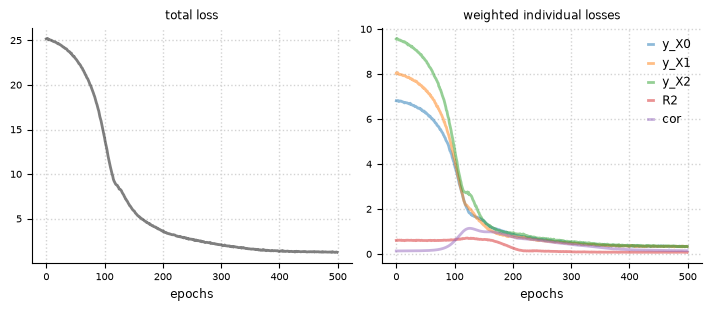

In [14]:
fit.plot.loss(figsize=(7, 3));

### Convergence of the prior marginals

A deep prior has no hyperparameter to plot. The plot shows the mean and
the standard deviation of each prior marginal. Each must settle on one
value.

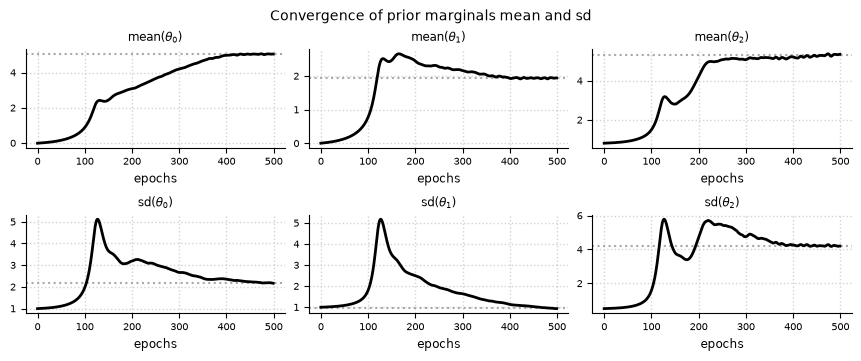

In [15]:
fit.plot.marginals(figsize=(8.5, 3.5));

### Expert expectations

Each point compares one elicited quantile of the expert with the same
quantile of the learned model. The points lie on the diagonal when the
learned prior reproduces the expert data.

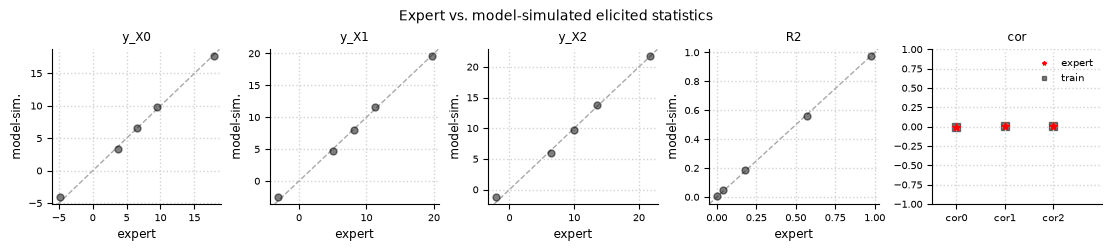

In [16]:
fit.plot.elicits(cols=5, figsize=(11, 2.4));

### Learned prior distributions

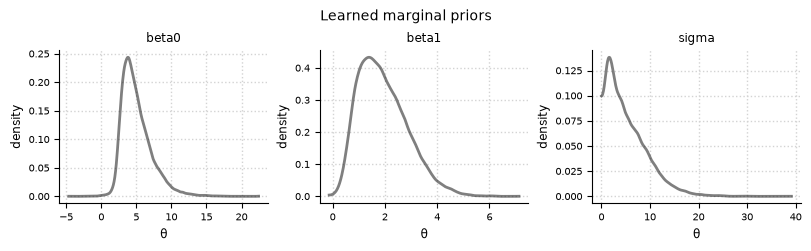

In [17]:
fit.plot.prior_marginals(cols=3, figsize=(8, 2.4));

### Learned joint prior

The joint prior shows the dependence between the model parameters. The
expert assumes independence, so the pairs must show no correlation.

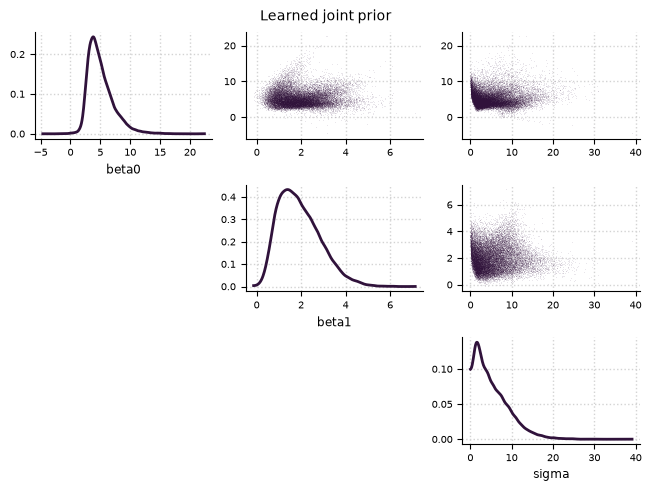

In [18]:
fit.plot.prior_joint();

## Next steps

We learned a joint prior with a normalizing flow.
We checked its marginals and its correlations with the plots.

- [Getting started with parametric priors][getting-started-with-parametric-priors] gives each parameter a prior family.
- The [how-to guides][how-to-guides] solve one task each, for example saving the `eliobj`.